In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

## 1 LOAD THE DATA

In [2]:
df = pd.read_csv("Housing.csv")
print("rows and column: ",df.shape)

rows and column:  (545, 13)


In [3]:
df.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


**observation - The dataset has 545 houses and 13 columns**

## 2 DATA QUALITY

In [4]:
print("Missing values :" , df.isnull().sum().sum())
print("Duplicate rows :" , df.duplicated().sum())
print()
print(df.dtypes)
print()
print(df.describe().round(1))

Missing values : 0
Duplicate rows : 0

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

            price     area  bedrooms  bathrooms  stories  parking
count       545.0    545.0     545.0      545.0    545.0    545.0
mean    4766729.2   5150.5       3.0        1.3      1.8      0.7
std     1870439.6   2170.1       0.7        0.5      0.9      0.9
min     1750000.0   1650.0       1.0        1.0      1.0      0.0
25%     3430000.0   3600.0       2.0        1.0      1.0      0.0
50%     4340000.0   4600.0       3.0        1.0      2.0      0.0
75%     5740000.0   6360.0       3.0        2.0      2.0      1.0
max    13300000.0  16200.0       6.0        4.0      4.0      3.0


**Observation - the dataset have 0 missing values and 0 duplicate rows , so no cleaning of data need
the data has 5 numeric feature area , bedrooms , bathrooms , storeis, parking and 7 text feature
6 yes and no columns and furnishngstatus** 

**prices range from 1750000 to 13300000 with mean of about 4766729 and a median 4340000**

## 3 EXPLORE THE PRICE OF HOUSES

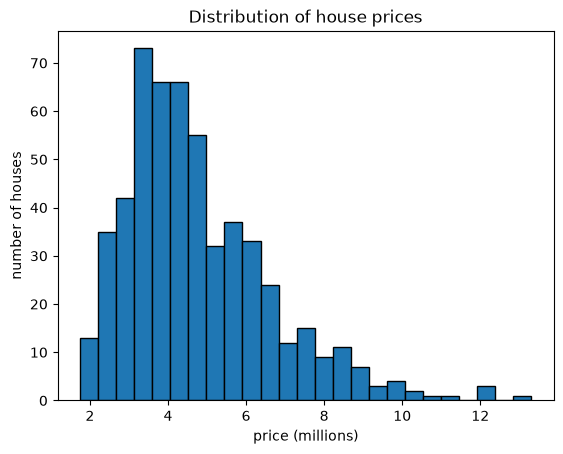

Price skewness:  1.21

bedrooms     0.37
parking      0.38
stories      0.42
bathrooms    0.52
area         0.54
Name: price, dtype: float64


In [5]:
plt.hist(df["price"] / 1_000_000, bins=25 ,edgecolor = 'black')
plt.xlabel("price (millions)")
plt.ylabel("number of houses")
plt.title("Distribution of house prices")
plt.show()

print('Price skewness: ' , round (df["price"].skew() , 2))
print()
print(df.select_dtypes(include="number").corr()["price"].drop("price").sort_values().round(2))



**observation - the prices distribution is skwed to the right (skweness 1.21)  most
house are cheaper and few are very expensive , so the mean is above the median**

*correlation with prices : area 0.54 , bathroom0.52 , stories 0.42 , parking 0.38 , bedrooms 0.37
no single house goes above 0.54*

## 5 Average price by category

In [6]:
for column in df.select_dtypes(exclude='number').columns:
    print(column)
    print(df.groupby(column)['price'].agg(['count' , 'mean']).round(0))
    print()

mainroad
          count       mean
mainroad                  
no           77  3398905.0
yes         468  4991777.0

guestroom
           count       mean
guestroom                  
no           448  4544546.0
yes           97  5792897.0

basement
          count       mean
basement                  
no          354  4509966.0
yes         191  5242615.0

hotwaterheating
                 count       mean
hotwaterheating                  
no                 520  4728593.0
yes                 25  5559960.0

airconditioning
                 count       mean
airconditioning                  
no                 373  4191940.0
yes                172  6013221.0

prefarea
          count       mean
prefarea                  
no          417  4425299.0
yes         128  5879046.0

furnishingstatus
                  count       mean
furnishingstatus                  
furnished           140  5495696.0
semi-furnished      227  4907524.0
unfurnished         178  4013831.0



**observation** - houseswith air conditioning average about 6.01M against 4.19M wihtout air conditioning 
area - 5.88M and 4.43M guest rom - 5.79M vs 4.54M 
main road - 4.99 m vs 3.40M , basement - 5.24M vs 4.51M

furnished houses average 5.50M , semi-furnished 4.91M and unfurnished 4.01M . 
Only 25 houses have hot water heating, so that average is less reliable these are avergaes not proof fo cause , beacuse bige house may simply have more of these feature

## 6 SPLIT THE DATA

In [7]:
from sklearn.model_selection import train_test_split
SEED = 42

In [8]:
x = df.drop(columns=['price'])
y= df['price']
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.2, random_state=SEED)
print("Train :" ,x_train.shape, "Test" , x_test.shape)


number_columns= x.select_dtypes(include="number").columns.tolist()
text_columns = x.select_dtypes(exclude="number").columns.tolist()


print("Numeric  columns :" , number_columns)
print("Number of text columns :",text_columns)

Train : (436, 12) Test (109, 12)
Numeric  columns : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Number of text columns : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


**here, Used 80% of the houses for training 436 and 20% for testing 109 with a fixed seed 42, so the split is the same on every time we execute**

## 7 PIPELINE PRE-PROCESS 

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [10]:
def make_pre_processor():
    number_steps = Pipeline([
        ('fill_missing' , SimpleImputer(strategy= "median")),
        ("scale" , StandardScaler()),
    ])



    text_steps = Pipeline([('fill_missing', SimpleImputer(strategy="most_frequent")),
                          ('onehot' , OneHotEncoder(handle_unknown ='ignore')),
                          ])
    return ColumnTransformer([
        ('numbers' , number_steps , number_columns),
        ('text' , text_steps , text_columns),
    ])

def make_pipeline(model):
    return Pipeline([('preprocess', make_pre_processor()), ("model" , model)])
    

**The preprocessing is built as pipeline , numeric columns are filled with the median if anything
is missing and scaled . txt columns are filled with the most common value and turned into 0/1 columns
same step run for every model and for any new data a fresh preprocessor is created for each model so models never share fitted steps this data has no missing value, but the filling steps keeps the pipeline safe for new data** 

## 8 Model and validation setup

In [11]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}



folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"rmse": "neg_root_mean_squared_error",
           "mae": "neg_mean_absolute_error",
           "r2": "r2"}

**I compared five models: Linear Regression, Ridge, Decision Tree max depth 5 Random Forest 200 trees and Gradient Boosting, plus a baseline that always guesses the average price.
Each model is scored with 5-fold cross-validation on the training data and then on the test set.**

## 9 Train and compare

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer

In [14]:
rows = []
fitted_pipelines = {}

avg_guess = np.full(len(y_test) , y_train.mean())
rows.append(["Baseline (average)", None , None , None,
            np.sqrt(mean_squared_error(y_test,avg_guess)),
            mean_absolute_error(y_test,avg_guess),
            r2_score(y_test, avg_guess)
            ])

In [15]:
for name, model in models.items():
    pipeline = make_pipeline(model)

    cv = cross_validate(pipeline, x_train, y_train , cv=folds , scoring=scoring)

    pipeline.fit(x_train,y_train)
    predictions = pipeline.predict(x_test)
    fitted_pipelines[name] = pipeline

    rows.append([name,
                 -cv["test_rmse"].mean(), -cv["test_mae"].mean(), cv["test_r2"].mean(),
                 np.sqrt(mean_squared_error(y_test,predictions)),
                 mean_absolute_error(y_test , predictions), 
                 r2_score(y_test , predictions)
                ])


results = pd.DataFrame(rows , columns=["model" , "cv_rmse" , "cv_mae" , "cv_r2",
                                      "test_rmse" , "test_mae", "test_r2"])
results = results.round({"cv_rmse" : 0 , "cv_mae" : 0 , "cv_r2" : 3, "test_rmse" : 0 , "test_mae" : 0,
                         "test_r2": 3})

results.to_csv("results.csv" , index= False)
results

,model,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2
0,Baseline (average),NaN,NaN,NaN,2268298.0,1748625.0,-0.018
1,Linear Regression,1023579.0,747209.0,0.649,1324507.0,970043.0,0.653
2,Ridge,1021738.0,740578.0,0.651,1333155.0,975645.0,0.648
3,Decision Tree,1363109.0,919325.0,0.365,1616965.0,1207531.0,0.483
4,Random Forest,1085010.0,766757.0,0.604,1398239.0,1015055.0,0.613
5,Gradient Boosting,1084589.0,763318.0,0.607,1299730.0,967227.0,0.666


**Baseline: always guessing the average price gives RMSE 2268298 and R²-0.018**
Test RMSE / R² cross-validation RMSE in brackets:
 Gradient Boosting: 1299730 / 0.666 (1084589)
 Linear Regression: 1324507 / 0.653 (1023579)
 Ridge: 1333155 / 0.648 (1021738)
 Random Forest: 1398239 / 0.613 (1085010) ,Decision Tree: 1616965 / 0.483 (1363109)


all the mdodels beat the baseline . the decision tree is clearly the weakest among all , other four are close together (test RMSE between 1.30M and 1.40M) ridges test RMSE is
about 41% lower than the baseline , and about 28% of the average price 

## 10  BEST MODEL USING CROSS - VALIDATION 

In [16]:
real_models = results[results['model'] != "Baseline (average)"]
best_name = real_models.sort_values("cv_rmse").iloc[0]["model"]


print("best model by cross validation RMSE :" , best_name)
print("best model by test RMSE :", real_models.sort_values("test_rmse").iloc[0]["model"])


best model by cross validation RMSE : Ridge
best model by test RMSE : Gradient Boosting


**Observation - by cross validation the best model is Ridge (RMSE 1021738, r2 0.651) with linear regression almost identical 1023579 on test set the best is gradient boosting with 1299730**

**and the gap between gradien boosting and ridge is only 33000 , the test set has 109 house. the final model by cross-validation and not by test score , because choosing by test score would make the test result optimise** 



## 11 COMPARISON CHART

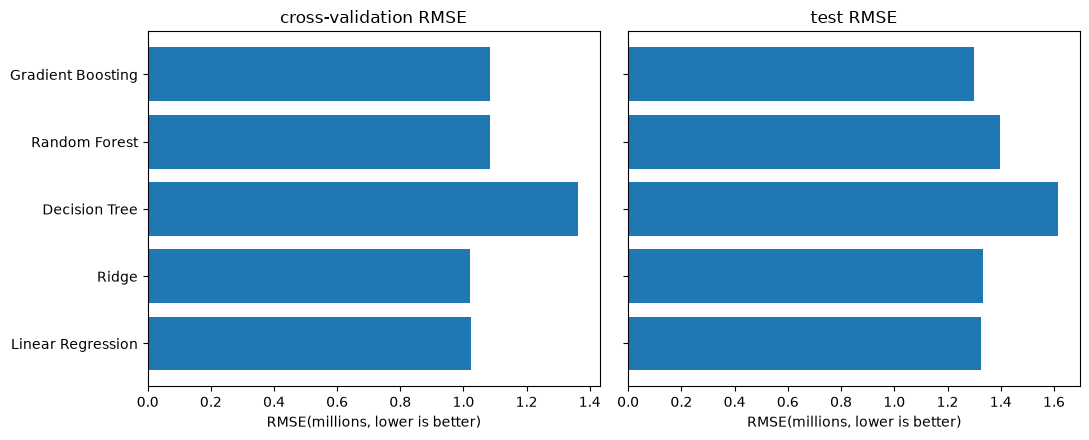

In [17]:
fig, axes = plt.subplots(1,2, figsize= (11, 4.5), sharey = True)
axes[0].barh(real_models ['model'] , real_models["cv_rmse"] / 1_000_000)
axes[0].set_title("cross-validation RMSE")
axes[1].barh(real_models['model'], real_models['test_rmse'] / 1_000_000)
axes[1].set_title("test RMSE")

for axis in axes:
    axis.set_xlabel("RMSE(millions, lower is better)")

plt.tight_layout()
plt.show()

**The charts show the same picture the decision tree has the highest error in both views and the other 4 models are close together the order of the top models changes between cross-validation and the test set.**

## 12 Predicted vc actual

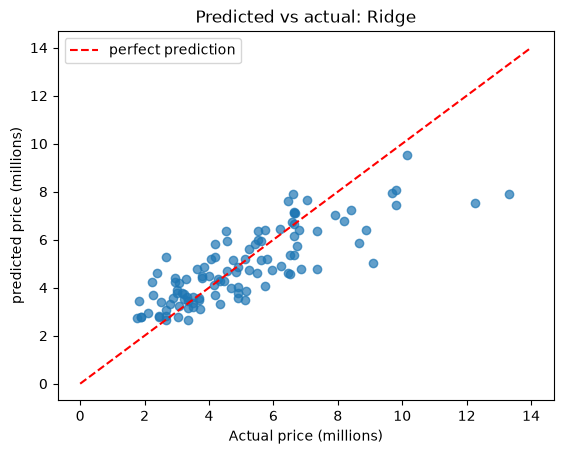

In [18]:
best_pipeline = fitted_pipelines[best_name]
best_predictions = best_pipeline.predict(x_test)


plt.scatter(y_test / 1_000_000 , best_predictions / 1_000_000 , alpha=0.7)
limit = [0, 14]
plt.plot(limit , limit, "r--" , label = "perfect prediction")
plt.xlabel("Actual price (millions)")
plt.ylabel("predicted price (millions)")
plt.title("Predicted vs actual: " + best_name)
plt.legend()
plt.show()


observation - 67 of 109 test house are predicted within 1 million of the actual price

expensive house are under predictied : the 11 house above 8M  have an average actual price
of 9.84M but an average prediction of 7.26M , the biggest miss is a house price at 13.3 M that was predicted at 7.9M


cheap house are ovver predicted the 32 house below 3.5 M average 2.73 M actual and 3.49 predicted 
the prediction stay between about 2.65M and 9.55M , so the model pulls extreme prices toward the middle

## 13 Feature importance

In [19]:
from sklearn.inspection import permutation_importance

area                236397.0
bathrooms           231834.0
stories             161793.0
airconditioning     153468.0
parking              73962.0
prefarea             71708.0
furnishingstatus     40320.0
mainroad             30875.0
hotwaterheating      20348.0
basement             15999.0
bedrooms             14164.0
guestroom            14016.0
dtype: float64


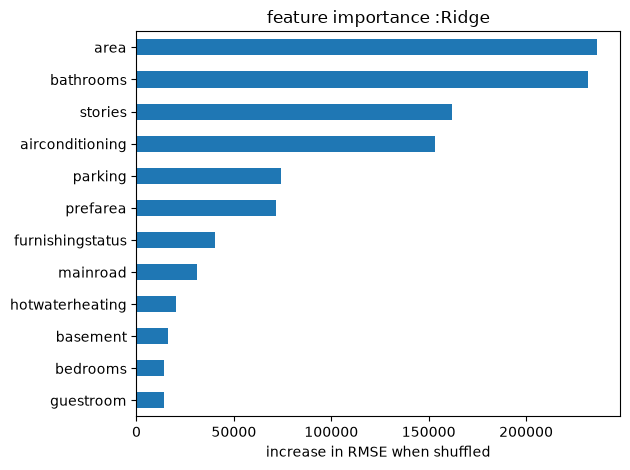

In [20]:
result = permutation_importance(best_pipeline , x_test , y_test , n_repeats=30, random_state = SEED,
                                scoring= "neg_root_mean_squared_error")

importance = pd.Series(result.importances_mean , index= x_test.columns)
importance = importance.sort_values(ascending=False)
print(importance.round(0))

importance.sort_values().plot(kind='barh')
plt.xlabel ("increase in RMSE when shuffled")
plt.title("feature importance :" + best_name )
plt.tight_layout()
plt.show()

                                

**observation** - 
permutaion importance on the testset shuffle one column at a time a bigger rise in RMSE means the model relied on it more 

area 236397 and bathroom 231834 matter most , followed by stories 161793 , airconditioning 153468 parking 73962 and perfarea 71708 , furnishingstatus 153468 

mainroad, hotwaterheating, basement, bedrooms and guestroom are small about 14000 to 40000
bedrooms correlates with price 0.37 but ranks low , probably because it overlaps with area bathrooms and stories. Importance shows what the model relies on not what causes prices to change.



## 14 Tuning 

In [21]:
search_settings = {
    "Ridge" : (Ridge(), {"model__alpha" :[0.1 , 1 , 10 , 30 , 100]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=SEED),
                         {"model__n_estimators" : [100 , 200],
                          "model__learning_rate" : [0.03 , 0.05 , 0.1], 
                          "model__max_depth" : [2,3]}),
}

In [22]:
for name , (model , grid) in search_settings.items():
    search = GridSearchCV(make_pipeline(model), grid , cv=folds, scoring="neg_root_mean_squared_error")
    search.fit(x_train , y_train)
    tuned_predictions = search.predict(x_test)
    print (name)

    print("best settings :" , search.best_params_)
    print("cv RMSE :" , round(-search.best_score_))
    print("test RMSE :", round(np.sqrt(mean_squared_error(y_test, tuned_predictions))),
          "test R2 :", round(r2_score(y_test, tuned_predictions), 3))

Ridge
best settings : {'model__alpha': 10}
cv RMSE : 1021738
test RMSE : 1333155 test R2 : 0.648
Gradient Boosting
best settings : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
cv RMSE : 1074420
test RMSE : 1328957 test R2 : 0.651


**observation**
Ridges - the best setting was alpha = 10 , the value i already used so nothing changed 
cross validation RMSE 1021738 , test RMSE 1333155 , R2 0.648.

gradient boosting - the best settings were learning rate 0.05 , max depth 3 and n_estimators 100 cross  validation RMSE improves slightly 1084589 to 1074420 about 0.9% , but test RMSE got worse fot worse 1299730 to 1328957 ; R2 0.666 to 0.651 and it is still behind ridge in cross validation. and tunning does not change winner 
    

## 15 use ppipeline on a new house 

In [23]:
import joblib

In [24]:
joblib.dump(best_pipeline, "housing_price_model.joblib")
loaded_pipelines = joblib.load("housing_price_model.joblib")


same = np.allclose(best_pipeline.predict(x_test) , loaded_pipelines.predict(x_test))
print("loaded model identical predictions :" , same)

new_house = pd.DataFrame([{
        'area': 6000, 'bedrooms': 3, "bathrooms": 2, "stories": 2,
    "mainroad": "yes","guestroom": "no", "basement": 'no',
    "hotwaterheating": 'no','airconditioning': "yes","parking": 1,
    "prefarea": 'no',"furnishingstatus": 'semi-furnished'
}])

print("predicted price of new house :" , round(loaded_pipelines.predict(new_house)[0]))

loaded model identical predictions : True
predicted price of new house : 6138847


**the best pipeline ridges with joblib and loaded it back it gives identical predictions on the test set true and it accepts a raw house with the 12 original columns and does all the preprocessing itself**

**for a house with area 6000 , 3 bedrooms ,2 bathrooms , 2 stories , main road , air conditioning , 1 parking space and semi furnished , the predicted price is 6138847**

## 16 Reproducibility check 

In [25]:
pipeline_again = make_pipeline(Ridge(alpha=10)).fit(x_train , y_train)
print("Re-built pipeline matches saved model: ", np.allclose(pipeline_again.predict(x_test),
                                                            loaded_pipelines.predict(x_test)))

Re-built pipeline matches saved model:  True


**rebuilding the same pipeline with the same seed and the same training data gives the same predictions as the saved model true 
reproducibility comes from 4 things : a fixed seed , one pipeline from raw data to prediction , saved model file , and pinned library ersions in requirement text**

#### conclusions 

- built a pipline from data loading to evaluation , including preprocessing , five model , comapriosn a saves model and a reproducibility check 
- all 5 models beat the baseline . ridges was best by cross - validation (RMSE 1021738 , R2 0.651) and scored RMSE 1333155 and r2 0.648 on the test set , about 41% lower error than the baseline 
- simple lienar model nathched or beat the forest and the decision tree was weakest 
- area , bathroom, stories and air conditioning mater most 
- tuning did not improve the result 


#### limitatons 
 - only 545 house and test set of 109 so small gaps between models are not reliable
- R2 is about 0.65 , so about a third of the variation in price is unexplained . a typical error is around 1.3M about 28% of the average price
- expensive house are under predicted and cheap ones over
- prices are right-skwed and not transform them 
- the data does not say where or when the prices were recorded 
- feature importance does not show cause and effect 
